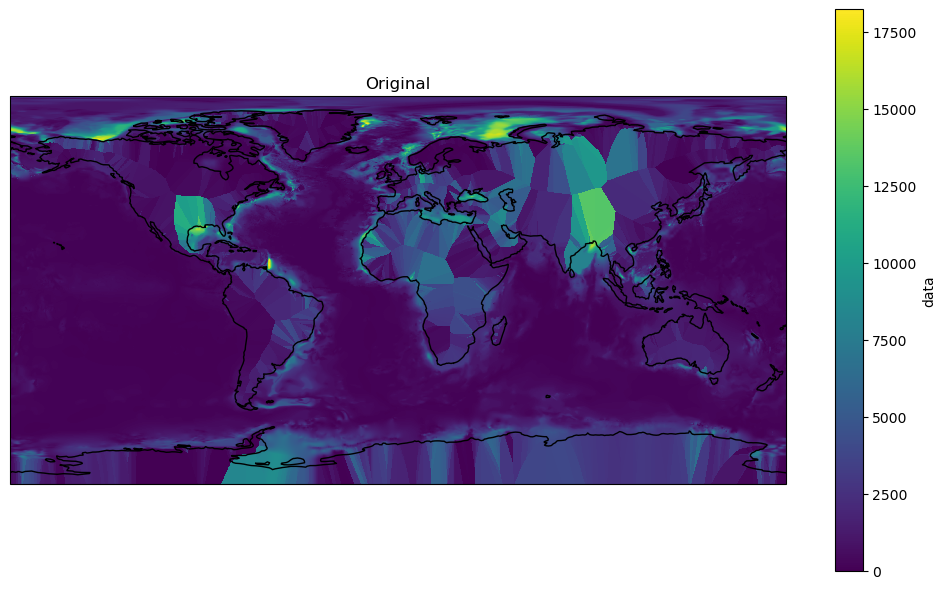

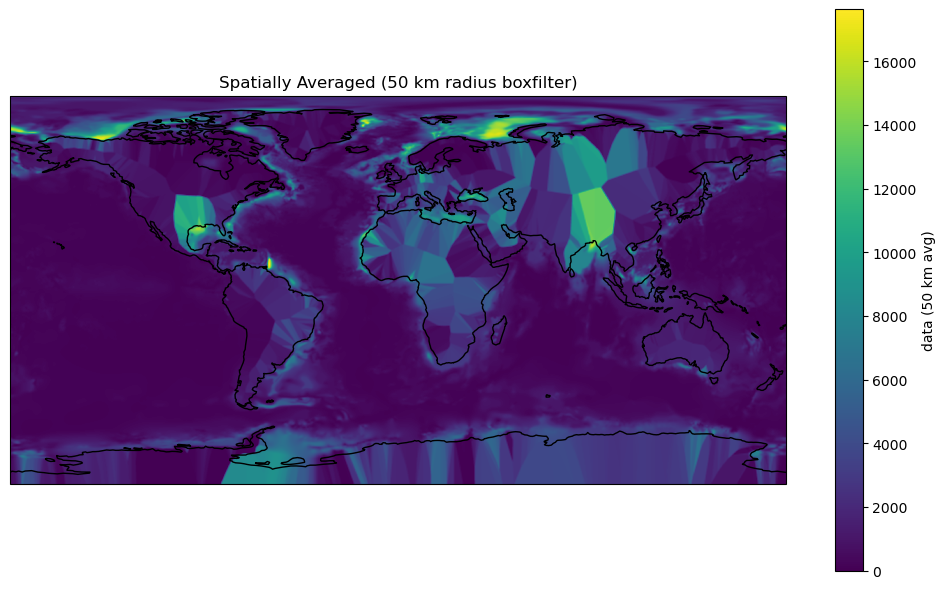

Saved 50 km r50km smoothed file to /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_TOT_SED_THICK_M_GLOBSED_Straume_r50km.5m.nc


In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.ndimage import uniform_filter
from pathlib import Path
import sys

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name in ('notebooks', 'notebooks') else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import DATA_RAW

# Path to file
nc_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated" / "GL_TOT_SED_THICK_M_GLOBSED_Straume.5m.nc"
nc_outpath = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated" / "GL_TOT_SED_THICK_M_GLOBSED_Straume_r50km.5m.nc"

# Load the NetCDF file
ds = xr.open_dataset(nc_path)

# Assume the main variable is named 'data'
varname = None
for v in ds.data_vars:
    if ds[v].shape == (2160, 4320):
        varname = v
        break
if varname is None:
    raise ValueError("Couldn't find main data variable of shape (2160, 4320)")

data = ds[varname]
lat = ds['lat']
lon = ds['lon']

# Plot original data
plt.figure(figsize=(10,6))
ax = plt.axes(projection=ccrs.PlateCarree())
im = ax.pcolormesh(lon, lat, data, transform=ccrs.PlateCarree(), cmap='viridis')
ax.coastlines()
plt.colorbar(im, label=varname)
plt.title('Original')
plt.tight_layout()
plt.show()

# Calculate 50 km radius in pixels
deg_per_pixel = (lat[1] - lat[0]).values
km_per_deg = 111  # at equator
km_per_pixel = deg_per_pixel * km_per_deg
radius_km = 50
radius_px = int(np.round(radius_km / km_per_pixel))

# Box filter size: diameter, must be odd & >= 1
size = max(1, 2 * radius_px + 1)

data_filled = np.where(np.isnan(data), 0, data)
mask = ~np.isnan(data)

smoothed_data = (
    uniform_filter(data_filled, size=size, mode='constant', cval=0) /
    uniform_filter(mask.astype(float), size=size, mode='constant', cval=0)
)
smoothed_data = np.where(mask, smoothed_data, np.nan)

# Plot spatially averaged data
plt.figure(figsize=(10,6))
ax = plt.axes(projection=ccrs.PlateCarree())
im = ax.pcolormesh(lon, lat, smoothed_data, transform=ccrs.PlateCarree(), cmap='viridis')
ax.coastlines()
plt.colorbar(im, label=f"{varname} (50 km avg)")
plt.title('Spatially Averaged (50 km radius boxfilter)')
plt.tight_layout()
plt.show()

# Save the r50km spatially averaged file
smoothed_da = xr.DataArray(
    smoothed_data,
    dims=data.dims,
    coords=data.coords,
    name=f"{varname}"
)
# Retain attrs if present
if hasattr(data, "attrs"):
    smoothed_da.attrs = data.attrs.copy()
# To maintain structure, create new dataset with all coords and the new variable
out_ds = xr.Dataset(
    {f"{varname}": smoothed_da},
    coords={c: data.coords[c] for c in data.dims}
)
# Also keep lat and lon as variables for convenience if not already in coords
if 'lat' not in out_ds:
    out_ds['lat'] = lat
if 'lon' not in out_ds:
    out_ds['lon'] = lon

out_ds.to_netcdf(nc_outpath)
print(f"Saved 50 km r50km smoothed file to {nc_outpath}")


Saved land-masked (flipped mask) antilog chlorophyll file to SS_CHLOROPHYLL_MG_M3_MODIS_Aqua_MISSION_MEANx.5m.antilog.landmasked.nc


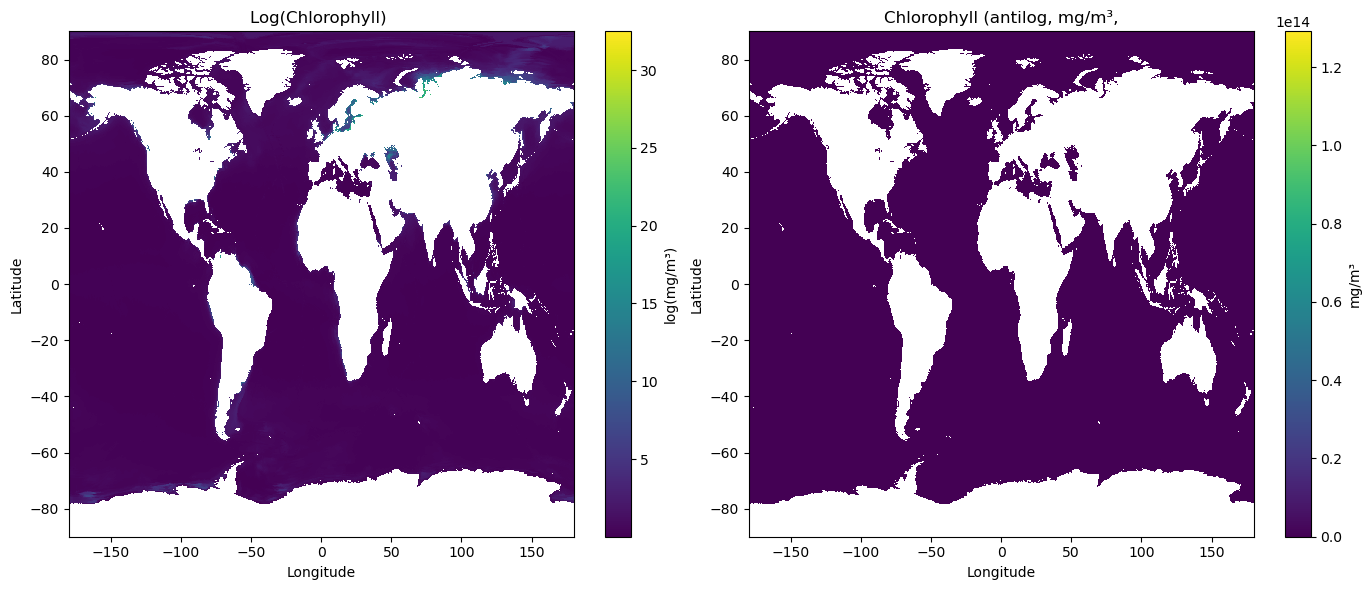

In [ ]:
# Chlorophyll features with "_LOG_" in the name are, by convention, stored as natural logarithms of the physical values (e.g., mg/m^3).# Therefore, it *does* make sense to take the antilog (i.e., exp) to recover the original units.# Some ocean color datasets provide log10 values, so you should inspect metadata,# but for Phrampus/Lee and MODIS Aqua these are usually ln-transformed (natural log).# Taking the antilog allows you to visualize and use the linear-scale chlorophyll for comparison and further modeling.# Below is the procedure for this specific feature, with a land mask applied in the same manner as Visualisation.ipynb.import xarray as xrimport numpy as npimport matplotlib.pyplot as pltfrom pathlib import Pathimport sys# Get project root and add to path (if not already done)try:    from utils import DATA_RAWexcept ImportError:    project_root = Path().resolve().parents[0] if Path().resolve().name in ('notebooks', 'notebooks') else Path().resolve()    if project_root.name != 'mtl-mar':        project_root = project_root.parent    sys.path.insert(0, str(project_root / "src"))    from utils import DATA_RAW# Path to the input file (log-transformed chlorophyll)chloro_logfile = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated" / "SS_CHLOROPHYLL_LOG_MG_M3_MODIS_Aqua_MISSION_MEANx.5m.grd"# Load the datasetlog_chlorophyll_ds = xr.open_dataset(chloro_logfile)# Try standard variable name or fallback to the only varif 'data' in log_chlorophyll_ds:    log_chlorophyll = log_chlorophyll_ds['data']else:    log_chlorophyll = list(log_chlorophyll_ds.data_vars.values())[0]# Antilog to recover linear chlorophyll (mg/m³)chlorophyll = np.exp(log_chlorophyll)# --- Apply land mask as in Visualisation.ipynb ---# Load land mask (should be the same shape/order as the data)# convention: 1 = land, 0 = oceanland_file = project_root / "data" / "raw" / "island_map.npy"land_map = np.load(land_file)# If land_map has any nan, treat as ocean (set to 1 means land)land_map[np.isnan(land_map)] = 1# Flip the land mask as in the provided example (twice 90deg rotation after a fliplr)land_mask_flipped = np.rot90(np.rot90(np.fliplr(land_map)))# If chlorophyll is xarray.DataArray, get numpy and keep metadata for restoringchloro_data = chlorophyll.values if isinstance(chlorophyll, xr.DataArray) else chlorophyll# Create land-masked arrays for both log and antilog versionslogchloro_masked = log_chlorophyll.values.copy()logchloro_masked[land_mask_flipped.astype(bool)] = np.nanchloro_masked = chloro_data.copy()chloro_masked[land_mask_flipped.astype(bool)] = np.nan# --- Save the antilog with land mask as DataArray with coords, dims, attrs as before ---chloro_antilog_da = xr.DataArray(    chloro_masked,    dims=log_chlorophyll.dims,    coords=log_chlorophyll.coords,    name='SS_CHLOROPHYLL_MG_M3_MODIS_Aqua_MISSION_MEANx')if hasattr(log_chlorophyll, "attrs"):    chloro_antilog_da.attrs = log_chlorophyll.attrs.copy()chloro_antilog_da.attrs['description'] = (    "Chlorophyll (mg/m^3), antilog of SS_CHLOROPHYLL_LOG_MG_M3_MODIS_Aqua_MISSION_MEANx.5m.grd, land masked (land=np.nan, mask flipped) following Visualisation.ipynb")chloro_antilog_ds = xr.Dataset({'SS_CHLOROPHYLL_MG_M3_MODIS_Aqua_MISSION_MEANx': chloro_antilog_da})chloro_antilog_ncfile = "SS_CHLOROPHYLL_MG_M3_MODIS_Aqua_MISSION_MEANx.5m.antilog.landmasked.nc"chloro_antilog_ds.to_netcdf(chloro_antilog_ncfile)print(f"Saved land-masked (flipped mask) antilog chlorophyll file to {chloro_antilog_ncfile}")# Plot the original log-chlorophyll and the antilog, both land-masked using the flipped maskplt.figure(figsize=(14,6))plt.subplot(1,2,1)plt.title("Log(Chlorophyll) ")lon = log_chlorophyll.coords.get('lon', None)lat = log_chlorophyll.coords.get('lat', None)if lon is not None and lat is not None:    plt.pcolormesh(lon, lat, logchloro_masked, shading='auto')    plt.xlabel("Longitude")    plt.ylabel("Latitude")else:    plt.imshow(logchloro_masked, aspect='auto')    plt.xlabel("X")    plt.ylabel("Y")plt.colorbar(label="log(mg/m³)")plt.tight_layout()plt.subplot(1,2,2)plt.title("Chlorophyll (antilog, mg/m³,")if lon is not None and lat is not None:    plt.pcolormesh(lon, lat, chloro_antilog_da, shading='auto')    plt.xlabel("Longitude")    plt.ylabel("Latitude")else:    plt.imshow(chloro_antilog_da, aspect='auto')    plt.xlabel("X")    plt.ylabel("Y")plt.colorbar(label="mg/m³")plt.tight_layout()plt.show()


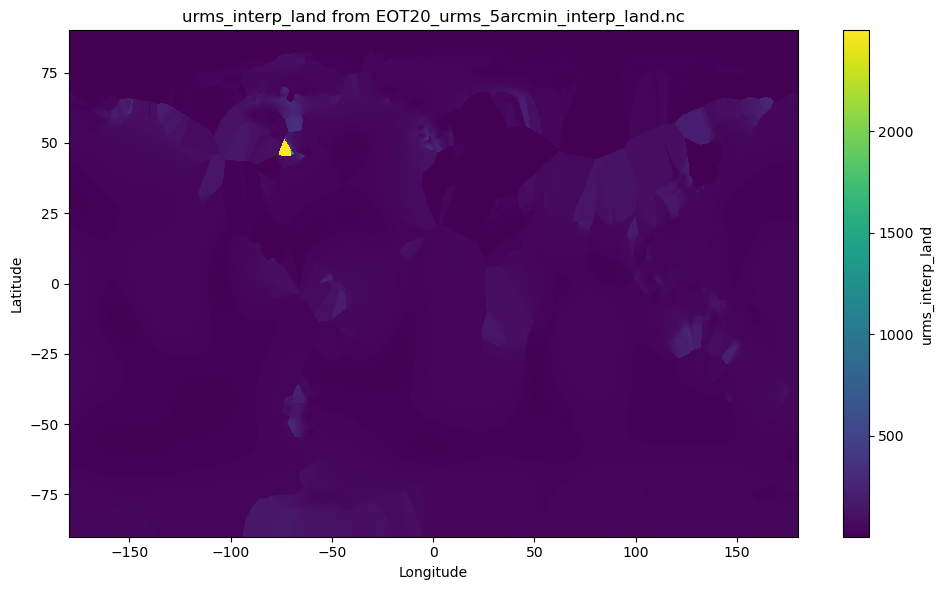

In [20]:
import xarray as xr
import matplotlib.pyplot as plt

# Load the NetCDF file
tide_nc_path = "/gxfs_work/cau/sunms498/work_old/Data/tides/ocean_tides/ocean_tides/derived_eot20_stats/EOT20_urms_5arcmin_interp_land.nc"
tide_ds = xr.open_dataset(tide_nc_path)

# Find the variable (assume it has only one data variable, or modify as needed)
data_var = list(tide_ds.data_vars)[0]
tide_data = tide_ds[data_var]

# Plotting
plt.figure(figsize=(10, 6))
lon = tide_data.coords.get('lon', None)
lat = tide_data.coords.get('lat', None)
plt.title(f"{data_var} from EOT20_urms_5arcmin_interp_land.nc")
if lon is not None and lat is not None:
    plt.pcolormesh(lon, lat, tide_data, shading='auto')
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
else:
    plt.imshow(tide_data, aspect='auto')
    plt.xlabel("X")
    plt.ylabel("Y")
plt.colorbar(label=str(tide_data.name))
plt.tight_layout()
plt.show()

In [21]:
tide_ds


<xarray.Dataset> Size: 37MB
Dimensions:           (lat: 2160, lon: 4320)
Coordinates:
  * lat               (lat) float64 17kB -90.0 -89.92 -89.83 ... 89.92 90.0
  * lon               (lon) float64 35kB -180.0 -179.9 -179.8 ... 179.9 180.0
Data variables:
    urms_interp_land  (lat, lon) float32 37MB 48.14 48.14 48.14 ... 5.486 5.486

Number of files found: 509


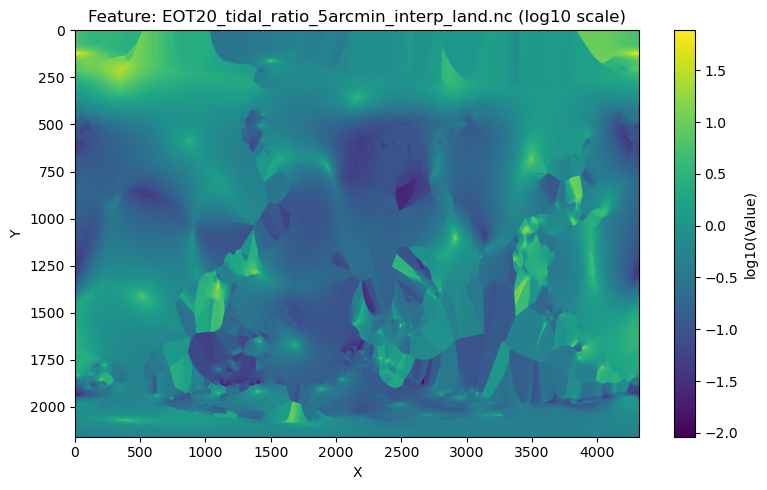

Displayed EOT20_tidal_ratio_5arcmin_interp_land.nc (1)


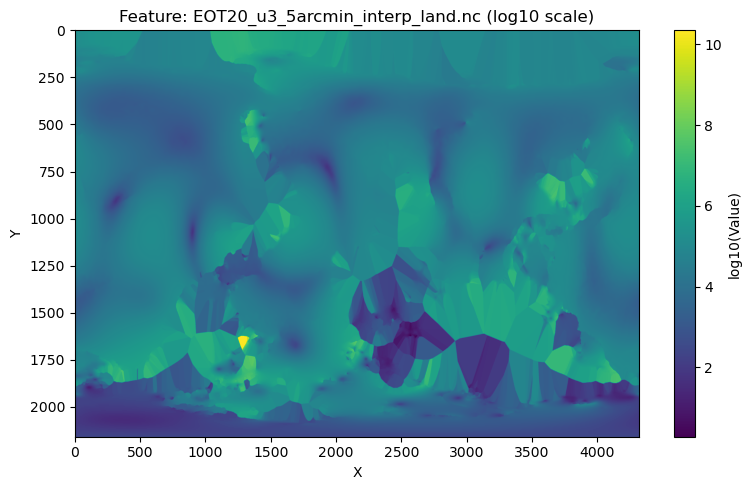

Displayed EOT20_u3_5arcmin_interp_land.nc (2)


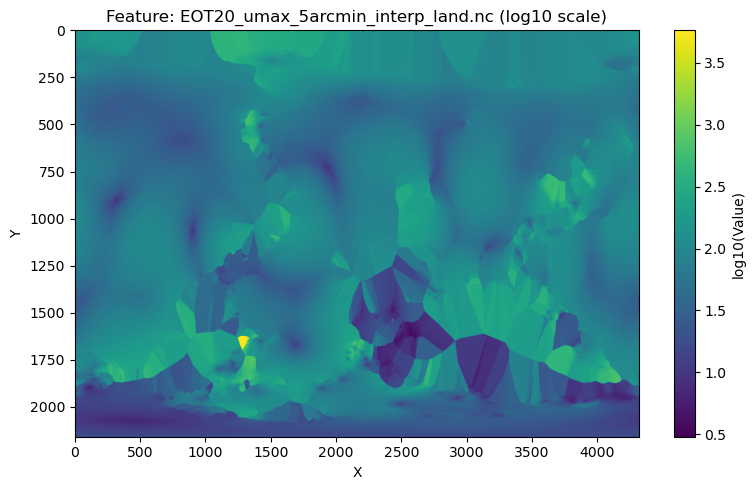

Displayed EOT20_umax_5arcmin_interp_land.nc (3)


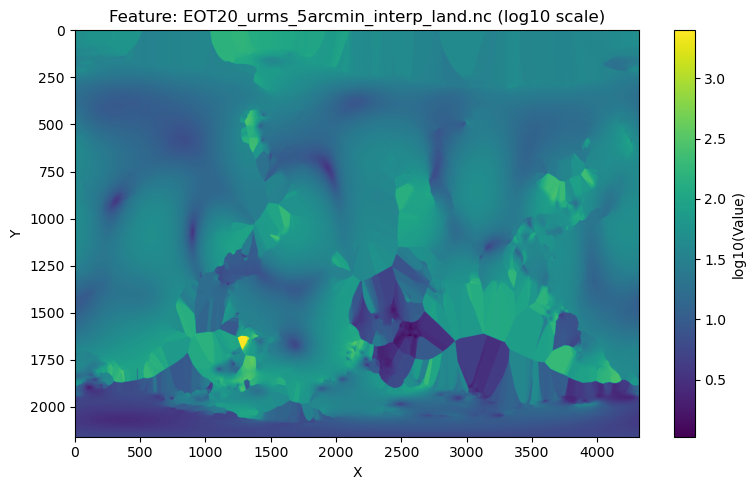

Displayed EOT20_urms_5arcmin_interp_land.nc (4)
Showing complete. 4 EOT files were displayed.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
import sys

# Get project root and add to path (if not already done)
try:
    from utils import DATA_RAW, DATA_INTERIM
except ImportError:
    project_root = Path().resolve().parents[0] if Path().resolve().name in ('notebooks', 'notebooks') else Path().resolve()
    if project_root.name != 'mtl-mar':
        project_root = project_root.parent
    sys.path.insert(0, str(project_root / "src"))
    from utils import DATA_RAW, DATA_INTERIM

# Define the input path containing the feature files
restrepo_input_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"

# List all feature files in the directory
restrepo_files = []
for (dirpath, dirnames, filenames) in walk(restrepo_input_path):
    restrepo_files.extend(filenames)
    break
restrepo_files.sort()
print(f"Number of files found: {len(restrepo_files)}")

# Read feature selection list (flatten to 1D set for easy lookup)
feature_selection = pd.read_csv(
    DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt"
).values.flatten()
feature_selection_set = set(feature_selection)

shown_files = 0
max_to_show = 10  # Limit to prevent plotting too many for interactivity

for file in restrepo_files:
    if not file.startswith("EOT"):
        continue
    if file not in feature_selection_set:
        continue
    file_path = restrepo_input_path / file
    try:
        ds = xr.open_dataset(file_path, format='NETCDF4')
        if 'data' in ds.variables:
            data = ds['data']
        elif 'z' in ds.variables:
            data = ds['z']
        else:
            print(f"Warning: No recognizable 'data' or 'z' variable in {file}, skipping.")
            continue
        arr = np.asarray(data)
        arr = np.where(np.abs(arr) > 1e36, np.nan, arr)

        # For log plotting, avoid log(0) and negative/NaN values
        arr_positive = np.where(arr > 0, arr, np.nan)
        if np.nanmin(arr_positive) <= 0 or np.isnan(arr_positive).all():
            print(f"Warning: Feature {file} has no positive values suitable for log plotting. Skipping.")
            continue

        plt.figure(figsize=(8, 5))
        im = plt.imshow(np.log10(arr_positive), aspect='auto', cmap='viridis')
        plt.title(f"Feature: {file} (log10 scale)")
        cbar = plt.colorbar(im, label='log10(Value)')
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.tight_layout()
        plt.show()
        shown_files += 1

        print(f"Displayed {file} ({shown_files})")

        if shown_files >= max_to_show:
            print("Reached the maximum number of displayed plots.")
            break

    except Exception as e:
        print(f"Error loading or plotting {file}: {e}")

print(f"Showing complete. {shown_files} EOT files were displayed.")
